<a href="https://colab.research.google.com/github/datqd/CNN-Blood-Cell-Classification/blob/main/notebooks/CNN_Blood_Cell_Classification_Notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Importing Libraries

In [2]:
import tensorflow as tf

print("TensorFlow version:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices('GPU'))

TensorFlow version: 2.21.0
GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [3]:
!pip install -q kaggle scikit-learn seaborn

In [4]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from collections import Counter
from pathlib import Path

from tensorflow.keras import layers, models
from tensorflow.keras.applications import VGG16, ResNet50

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score
)

SEED = 42

np.random.seed(SEED)
tf.random.set_seed(SEED)

print("Libraries successfully imported!")

Libraries successfully imported!


# Importing Data

In [5]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("unclesamulus/blood-cells-image-dataset")

print("Path to dataset files:", path)

100%|██████████| 268M/268M [00:15<00:00, 18.0MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/unclesamulus/blood-cells-image-dataset/versions/2


In [6]:
dataset_path = path

In [7]:
for root, dirs, files in os.walk(dataset_path):

    level = root.replace(dataset_path, "").count(os.sep)

    if level <= 3:

        print("  " * level + os.path.basename(root) + "/")

        for file in files[:5]:

            print("  " * (level + 1) + file)

2/
  bloodcells_dataset/
    erythroblast/
      ERB_99360.jpg
      ERB_518664.jpg
      ERB_97746.jpg
      ERB_69914.jpg
      ERB_723032.jpg
    basophil/
      BA_904365.jpg
      BA_519510.jpg
      BA_221009.jpg
      BA_446850.jpg
      BA_577892.jpg
    monocyte/
      MO_294849.jpg
      MO_664159.jpg
      MO_654471.jpg
      MO_275440.jpg
      MO_729326.jpg
    eosinophil/
      EO_55694.jpg
      EO_675962.jpg
      EO_264654.jpg
      EO_648962.jpg
      EO_533476.jpg
    ig/
      MY_379326.jpg
      PMY_20723.jpg
      MY_378707.jpg
      PMY_822968.jpg
      MMY_712340.jpg
    neutrophil/
      BNE_890664.jpg
      SNE_537361.jpg
      BNE_592960.jpg
      BNE_715693.jpg
      BNE_476007.jpg
    platelet/
      PLATELET_406357.jpg
      PLATELET_804318.jpg
      PLATELET_191962.jpg
      PLATELET_887581.jpg
      PLATELET_884281.jpg
    lymphocyte/
      LY_933374.jpg
      LY_86378.jpg
      LY_447658.jpg
      LY_872921.jpg
      LY_404823.jpg


In [8]:
image_extensions = {".jpg", ".jpeg", ".png", ".bmp"}

image_paths = []

for path in Path(dataset_path).rglob("*"):

    if path.suffix.lower() in image_extensions:

        image_paths.append(str(path))

print("Total images found:", len(image_paths))

print("\nExample image paths:")

for path in image_paths[:10]:

    print(path)

Total images found: 17092

Example image paths:
/root/.cache/kagglehub/datasets/unclesamulus/blood-cells-image-dataset/versions/2/bloodcells_dataset/erythroblast/ERB_99360.jpg
/root/.cache/kagglehub/datasets/unclesamulus/blood-cells-image-dataset/versions/2/bloodcells_dataset/erythroblast/ERB_518664.jpg
/root/.cache/kagglehub/datasets/unclesamulus/blood-cells-image-dataset/versions/2/bloodcells_dataset/erythroblast/ERB_97746.jpg
/root/.cache/kagglehub/datasets/unclesamulus/blood-cells-image-dataset/versions/2/bloodcells_dataset/erythroblast/ERB_69914.jpg
/root/.cache/kagglehub/datasets/unclesamulus/blood-cells-image-dataset/versions/2/bloodcells_dataset/erythroblast/ERB_723032.jpg
/root/.cache/kagglehub/datasets/unclesamulus/blood-cells-image-dataset/versions/2/bloodcells_dataset/erythroblast/ERB_649651.jpg
/root/.cache/kagglehub/datasets/unclesamulus/blood-cells-image-dataset/versions/2/bloodcells_dataset/erythroblast/ERB_479284.jpg
/root/.cache/kagglehub/datasets/unclesamulus/blood-c

In [9]:
for path in image_paths[:20]:

    print(path.split("/")[-2])

erythroblast
erythroblast
erythroblast
erythroblast
erythroblast
erythroblast
erythroblast
erythroblast
erythroblast
erythroblast
erythroblast
erythroblast
erythroblast
erythroblast
erythroblast
erythroblast
erythroblast
erythroblast
erythroblast
erythroblast


In [10]:
def get_label_and_split(path):

    parts = Path(path).parts

    split_names = {
        "train": "train",
        "training": "train",
        "test": "test",
        "testing": "test",
        "valid": "val",
        "validation": "val"
    }

    split = None
    label = None

    for i, part in enumerate(parts):

        if part.lower() in split_names:

            split = split_names[part.lower()]

            if i + 1 < len(parts) - 1:
                label = parts[i + 1]

            break

    if label is None:
        label = Path(path).parent.name

    return label, split


data = []

for path in image_paths:

    label, split = get_label_and_split(path)

    data.append({
        "image_path": path,
        "label": label,
        "split": split
    })

df = pd.DataFrame(data)

print(df.head())

print("\nTotal images:", len(df))

print("\nBlood cell categories:")
print(df["label"].unique())

                                          image_path         label split
0  /root/.cache/kagglehub/datasets/unclesamulus/b...  erythroblast  None
1  /root/.cache/kagglehub/datasets/unclesamulus/b...  erythroblast  None
2  /root/.cache/kagglehub/datasets/unclesamulus/b...  erythroblast  None
3  /root/.cache/kagglehub/datasets/unclesamulus/b...  erythroblast  None
4  /root/.cache/kagglehub/datasets/unclesamulus/b...  erythroblast  None

Total images: 17092

Blood cell categories:
['erythroblast' 'basophil' 'monocyte' 'eosinophil' 'ig' 'neutrophil'
 'platelet' 'lymphocyte']


label
neutrophil      3329
eosinophil      3117
ig              2895
platelet        2348
erythroblast    1551
monocyte        1420
basophil        1218
lymphocyte      1214
Name: count, dtype: int64


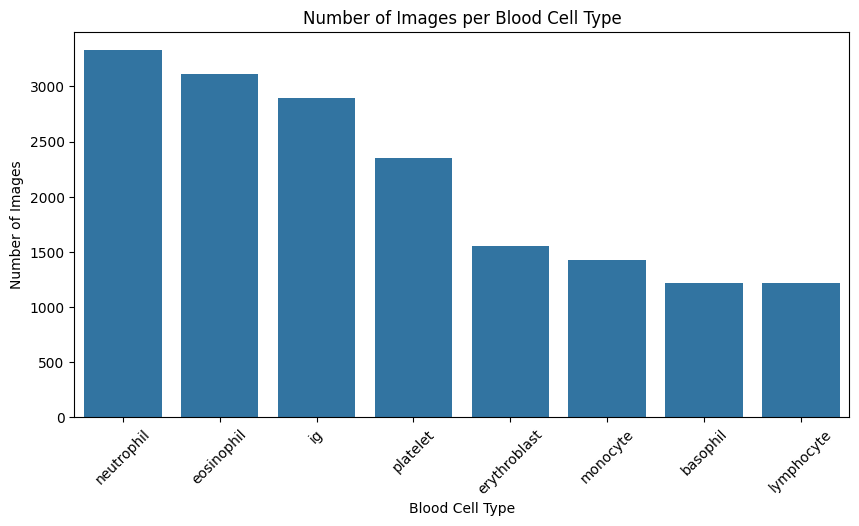

In [11]:
class_distribution = df["label"].value_counts()

print(class_distribution)

plt.figure(figsize=(10,5))

sns.barplot(
    x=class_distribution.index,
    y=class_distribution.values
)

plt.title("Number of Images per Blood Cell Type")
plt.xlabel("Blood Cell Type")
plt.ylabel("Number of Images")

plt.xticks(rotation=45)

plt.show()

In [12]:
if "train" in df["split"].values and "test" in df["split"].values:

    train_data = df[df["split"] == "train"].copy()

    test_data = df[df["split"] == "test"].copy()

    if "val" in df["split"].values:

        val_data = df[df["split"] == "val"].copy()

    else:

        train_data, val_data = train_test_split(
            train_data,
            test_size=0.20,
            random_state=SEED,
            stratify=train_data["label"]
        )

else:

    train_data, temporary_data = train_test_split(
        df,
        test_size=0.30,
        random_state=SEED,
        stratify=df["label"]
    )

    val_data, test_data = train_test_split(
        temporary_data,
        test_size=0.50,
        random_state=SEED,
        stratify=temporary_data["label"]
    )


print("Training images:", len(train_data))
print("Validation images:", len(val_data))
print("Testing images:", len(test_data))

Training images: 11964
Validation images: 2564
Testing images: 2564


In [13]:
class_names = sorted(df["label"].unique())

num_classes = len(class_names)

class_to_index = {
    name: index for index, name in enumerate(class_names)
}

train_data["label_id"] = train_data["label"].map(class_to_index)

val_data["label_id"] = val_data["label"].map(class_to_index)

test_data["label_id"] = test_data["label"].map(class_to_index)

print("Blood cell categories:", class_names)

print("Number of classes:", num_classes)

Blood cell categories: ['basophil', 'eosinophil', 'erythroblast', 'ig', 'lymphocyte', 'monocyte', 'neutrophil', 'platelet']
Number of classes: 8


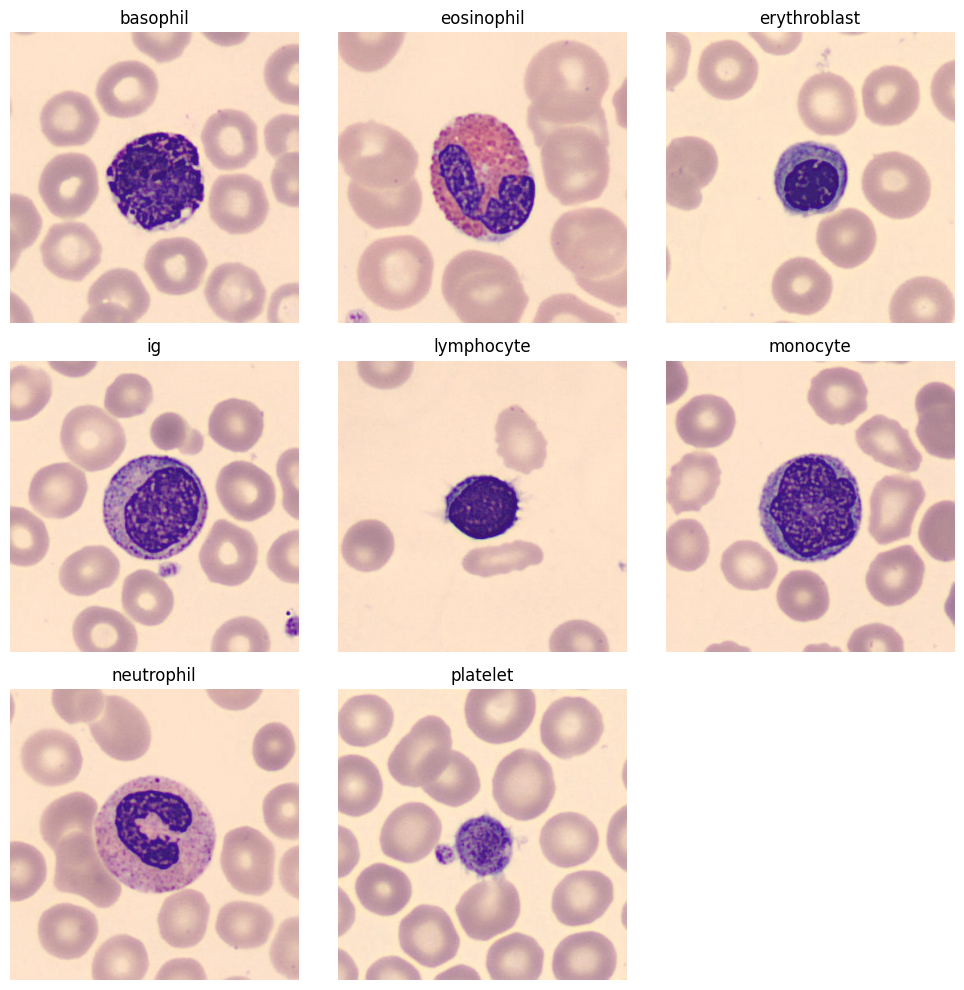

In [14]:
plt.figure(figsize=(10, 10))

for i, class_name in enumerate(class_names):

    sample_path = train_data[
        train_data["label"] == class_name
    ]["image_path"].iloc[0]

    image = plt.imread(sample_path)

    plt.subplot(
        (num_classes + 2) // 3,
        3,
        i + 1
    )

    plt.imshow(image)

    plt.title(class_name)

    plt.axis("off")

plt.tight_layout()

plt.show()

In [15]:
IMG_SIZE = (128, 128)

BATCH_SIZE = 32

In [16]:
def load_image(image_path, label):

    image = tf.io.read_file(image_path)

    image = tf.io.decode_image(
        image,
        channels=3,
        expand_animations=False
    )

    image = tf.image.resize(
        image,
        IMG_SIZE
    )

    image = tf.cast(image, tf.float32)

    image.set_shape((128, 128, 3))

    return image, label

In [17]:
def create_dataset(data, shuffle=False):

    paths = data["image_path"].values

    labels = data["label_id"].values

    dataset = tf.data.Dataset.from_tensor_slices(
        (paths, labels)
    )

    if shuffle:

        dataset = dataset.shuffle(
            buffer_size=len(data),
            seed=SEED
        )

    dataset = dataset.map(
        load_image,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    dataset = dataset.batch(BATCH_SIZE)

    dataset = dataset.prefetch(tf.data.AUTOTUNE)

    return dataset

In [18]:
train_ds = create_dataset(train_data, shuffle=True)

val_ds = create_dataset(val_data)

test_ds = create_dataset(test_data)

print("Datasets successfully created!")

Datasets successfully created!


In [19]:
data_augmentation = models.Sequential([

    layers.RandomFlip("horizontal"),

    layers.RandomRotation(0.10),

    layers.RandomZoom(0.10)

])

# Simple CNN Model

In [20]:
cnn_model = models.Sequential([

    layers.Input(shape=(128, 128, 3)),

    data_augmentation,

    layers.Rescaling(1./255),

    layers.Conv2D(
        32,
        (3,3),
        activation="relu"
    ),

    layers.MaxPooling2D((2,2)),

    layers.Conv2D(
        64,
        (3,3),
        activation="relu"
    ),

    layers.MaxPooling2D((2,2)),

    layers.Conv2D(
        128,
        (3,3),
        activation="relu"
    ),

    layers.MaxPooling2D((2,2)),

    layers.Flatten(),

    layers.Dense(
        128,
        activation="relu"
    ),

    layers.Dropout(0.5),

    layers.Dense(
        num_classes,
        activation="softmax"
    )

])

In [21]:
cnn_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │         1,032 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,305,672 (12.61 MB)

 Trainable params: 3,305,672 (12.61 MB)

 Non-trainable params: 0 (0.00 B)

In [22]:
cnn_model.compile(

    optimizer="adam",

    loss="sparse_categorical_crossentropy",

    metrics=["accuracy"]

)


early_stop_cnn = tf.keras.callbacks.EarlyStopping(

    monitor="val_loss",

    patience=4,

    restore_best_weights=True

)


history_cnn = cnn_model.fit(

    train_ds,

    validation_data=val_ds,

    epochs=20,

    callbacks=[early_stop_cnn]

)

Epoch 1/20
374/374 ━━━━━━━━━━━━━━━━━━━━ 27s 53ms/step - accuracy: 0.4427 - loss: 1.4463 - val_accuracy: 0.6950 - val_loss: 0.8494
Epoch 2/20
374/374 ━━━━━━━━━━━━━━━━━━━━ 30s 39ms/step - accuracy: 0.6145 - loss: 1.0359 - val_accuracy: 0.7067 - val_loss: 0.7744
Epoch 3/20
374/374 ━━━━━━━━━━━━━━━━━━━━ 14s 39ms/step - accuracy: 0.6592 - loss: 0.9131 - val_accuracy: 0.7516 - val_loss: 0.6646
Epoch 4/20
374/374 ━━━━━━━━━━━━━━━━━━━━ 21s 40ms/step - accuracy: 0.7129 - loss: 0.7734 - val_accuracy: 0.8233 - val_loss: 0.5259
Epoch 5/20
374/374 ━━━━━━━━━━━━━━━━━━━━ 15s 40ms/step - accuracy: 0.7538 - loss: 0.6658 - val_accuracy: 0.8358 - val_loss: 0.4892
Epoch 6/20
374/374 ━━━━━━━━━━━━━━━━━━━━ 20s 40ms/step - accuracy: 0.7796 - loss: 0.6035 - val_accuracy: 0.8417 - val_loss: 0.4401
Epoch 7/20
374/374 ━━━━━━━━━━━━━━━━━━━━ 14s 38ms/step - accuracy: 0.8027 - loss: 0.5564 - val_accuracy: 0.7956 - val_loss: 0.5235
Epoch 8/20
374/374 ━━━━━━━━━━━━━━━━━━━━ 15s 40ms/step - accuracy: 0.8173 - loss: 0.5129 - 

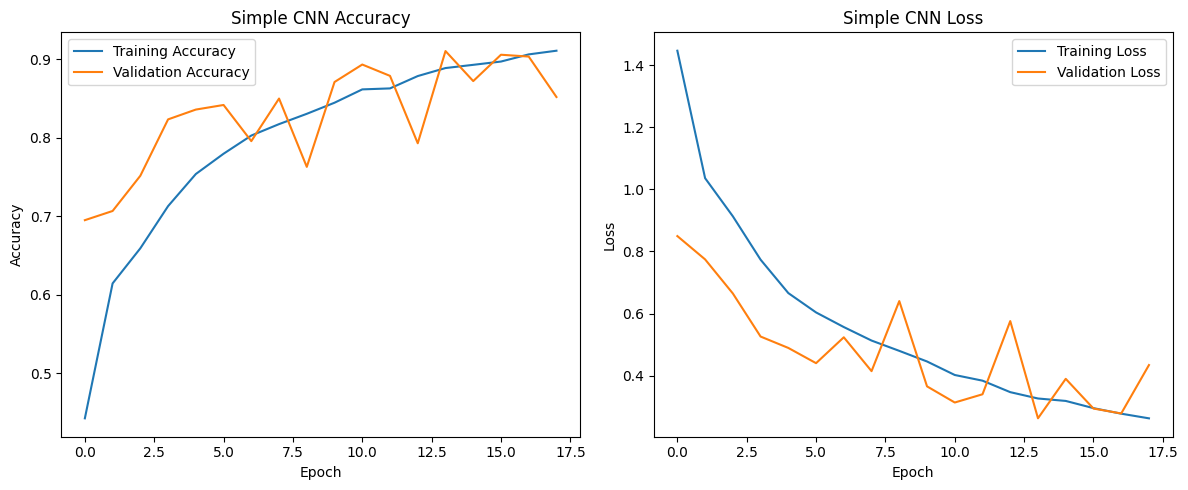

In [23]:
plt.figure(figsize=(12,5))

# Accuracy
plt.subplot(1,2,1)

plt.plot(
    history_cnn.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history_cnn.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.title("Simple CNN Accuracy")

plt.xlabel("Epoch")

plt.ylabel("Accuracy")

plt.legend()


# Loss
plt.subplot(1,2,2)

plt.plot(
    history_cnn.history["loss"],
    label="Training Loss"
)

plt.plot(
    history_cnn.history["val_loss"],
    label="Validation Loss"
)

plt.title("Simple CNN Loss")

plt.xlabel("Epoch")

plt.ylabel("Loss")

plt.legend()

plt.tight_layout()

plt.show()

In [24]:
pip install visualkeras


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 39.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [visualkeras]


/usr/local/lib/python3.13/dist-packages/visualkeras/layered.py:854: UserWarning: The legend_text_spacing_offset parameter is deprecated and will be removed in a future release.
  warnings.warn("The legend_text_spacing_offset parameter is deprecated and will be removed in a future release.")


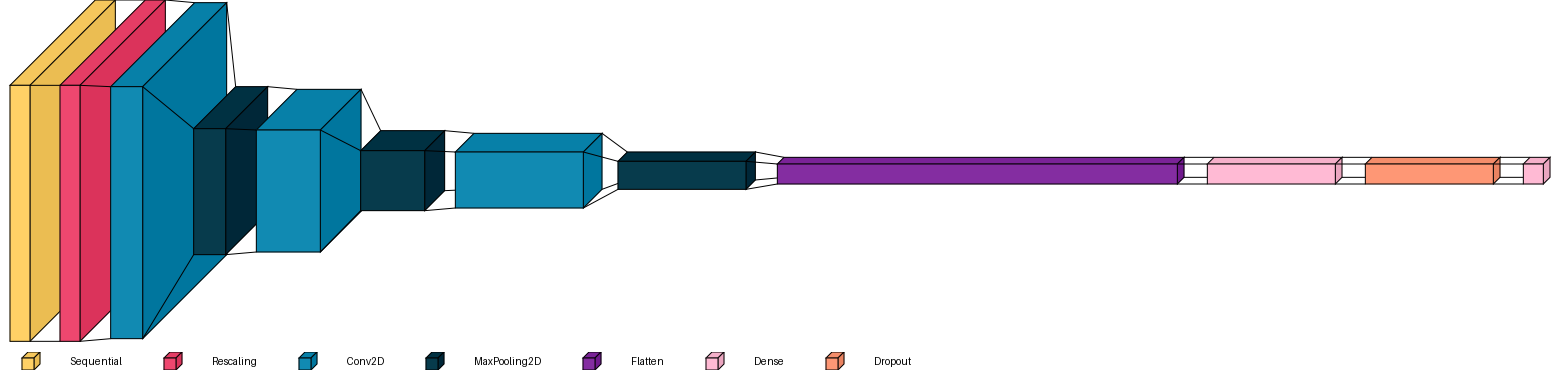

In [25]:
import visualkeras
from PIL import ImageFont
from IPython.display import display

# Create the CNN architecture visualization
cnn_architecture=visualkeras.layered_view(
    cnn_model,
    legend=True,
    draw_volume=True,
    scale_xy=2,
    scale_z=1,
    spacing=30
)

display(cnn_architecture)

# VGG16 Model

In [26]:
vgg_base = VGG16(

    weights="imagenet",

    include_top=False,

    input_shape=(128, 128, 3)

)

vgg_base.trainable = False

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 4s 0us/step


In [27]:
vgg_model = models.Sequential([

    layers.Input(shape=(128, 128, 3)),

    models.Sequential([

        layers.RandomFlip("horizontal"),

        layers.RandomRotation(0.10),

        layers.RandomZoom(0.10)

    ]),

    layers.Lambda(
        tf.keras.applications.vgg16.preprocess_input
    ),

    vgg_base,

    layers.GlobalAveragePooling2D(),

    layers.Dense(
        128,
        activation="relu"
    ),

    layers.Dropout(0.5),

    layers.Dense(
        num_classes,
        activation="softmax"
    )

])

In [28]:
vgg_model.compile(

    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.0001
    ),

    loss="sparse_categorical_crossentropy",

    metrics=["accuracy"]

)


early_stop_vgg = tf.keras.callbacks.EarlyStopping(

    monitor="val_loss",

    patience=4,

    restore_best_weights=True

)


history_vgg = vgg_model.fit(

    train_ds,

    validation_data=val_ds,

    epochs=20,

    callbacks=[early_stop_vgg]

)

Epoch 1/20
374/374 ━━━━━━━━━━━━━━━━━━━━ 38s 86ms/step - accuracy: 0.2197 - loss: 4.7495 - val_accuracy: 0.3857 - val_loss: 1.7464
Epoch 2/20
374/374 ━━━━━━━━━━━━━━━━━━━━ 25s 66ms/step - accuracy: 0.3256 - loss: 1.9718 - val_accuracy: 0.4423 - val_loss: 1.5472
Epoch 3/20
374/374 ━━━━━━━━━━━━━━━━━━━━ 25s 68ms/step - accuracy: 0.3740 - loss: 1.7241 - val_accuracy: 0.4743 - val_loss: 1.4444
Epoch 4/20
374/374 ━━━━━━━━━━━━━━━━━━━━ 24s 63ms/step - accuracy: 0.4111 - loss: 1.5980 - val_accuracy: 0.4992 - val_loss: 1.3547
Epoch 5/20
374/374 ━━━━━━━━━━━━━━━━━━━━ 24s 64ms/step - accuracy: 0.4519 - loss: 1.5010 - val_accuracy: 0.5339 - val_loss: 1.2662
Epoch 6/20
374/374 ━━━━━━━━━━━━━━━━━━━━ 24s 65ms/step - accuracy: 0.4698 - loss: 1.4308 - val_accuracy: 0.5589 - val_loss: 1.2076
Epoch 7/20
374/374 ━━━━━━━━━━━━━━━━━━━━ 23s 62ms/step - accuracy: 0.4986 - loss: 1.3659 - val_accuracy: 0.5550 - val_loss: 1.1899
Epoch 8/20
374/374 ━━━━━━━━━━━━━━━━━━━━ 24s 63ms/step - accuracy: 0.5122 - loss: 1.3257 - 

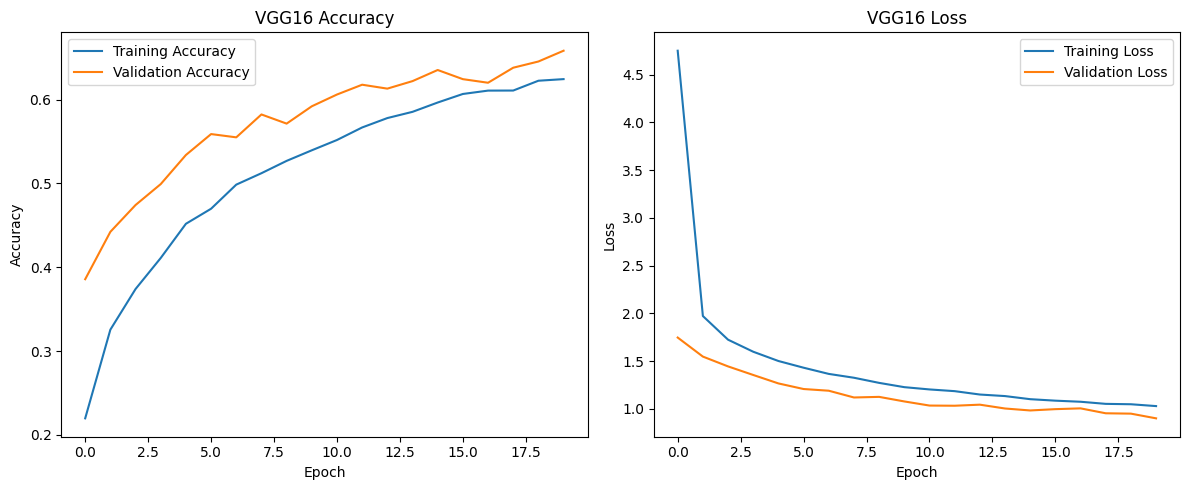

In [29]:
plt.figure(figsize=(12,5))

plt.subplot(1,2,1)

plt.plot(
    history_vgg.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history_vgg.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.title("VGG16 Accuracy")

plt.xlabel("Epoch")

plt.ylabel("Accuracy")

plt.legend()


plt.subplot(1,2,2)

plt.plot(
    history_vgg.history["loss"],
    label="Training Loss"
)

plt.plot(
    history_vgg.history["val_loss"],
    label="Validation Loss"
)

plt.title("VGG16 Loss")

plt.xlabel("Epoch")

plt.ylabel("Loss")

plt.legend()

plt.tight_layout()

plt.show()

In [30]:
# VGG16 with 50 Epochs
vgg_model_50 = models.Sequential([

    layers.Input(shape=(128, 128, 3)),

    models.Sequential([

        layers.RandomFlip("horizontal"),

        layers.RandomRotation(0.10),

        layers.RandomZoom(0.10)

    ]),

    layers.Lambda(
        tf.keras.applications.vgg16.preprocess_input
    ),

    vgg_base,

    layers.GlobalAveragePooling2D(),

    layers.Dense(
        128,
        activation="relu"
    ),

    layers.Dropout(0.5),

    layers.Dense(
        num_classes,
        activation="softmax"
    )

])


vgg_model_50.compile(

    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.0001
    ),

    loss="sparse_categorical_crossentropy",

    metrics=["accuracy"]

)


early_stop_vgg_50 = tf.keras.callbacks.EarlyStopping(

    monitor="val_loss",

    patience=4,

    restore_best_weights=True

)


history_vgg_50 = vgg_model_50.fit(

    train_ds,

    validation_data=val_ds,

    epochs=50,

    callbacks=[early_stop_vgg_50]

)

Epoch 1/50
374/374 ━━━━━━━━━━━━━━━━━━━━ 26s 66ms/step - accuracy: 0.2026 - loss: 3.9560 - val_accuracy: 0.3198 - val_loss: 1.8261
Epoch 2/50
374/374 ━━━━━━━━━━━━━━━━━━━━ 24s 63ms/step - accuracy: 0.3085 - loss: 1.9081 - val_accuracy: 0.4247 - val_loss: 1.6077
Epoch 3/50
374/374 ━━━━━━━━━━━━━━━━━━━━ 24s 63ms/step - accuracy: 0.3680 - loss: 1.7211 - val_accuracy: 0.4832 - val_loss: 1.4597
Epoch 4/50
374/374 ━━━━━━━━━━━━━━━━━━━━ 23s 62ms/step - accuracy: 0.4092 - loss: 1.5913 - val_accuracy: 0.5051 - val_loss: 1.3613
Epoch 5/50
374/374 ━━━━━━━━━━━━━━━━━━━━ 23s 62ms/step - accuracy: 0.4411 - loss: 1.4936 - val_accuracy: 0.5304 - val_loss: 1.2927
Epoch 6/50
374/374 ━━━━━━━━━━━━━━━━━━━━ 23s 62ms/step - accuracy: 0.4623 - loss: 1.4429 - val_accuracy: 0.5417 - val_loss: 1.2541
Epoch 7/50
374/374 ━━━━━━━━━━━━━━━━━━━━ 42s 66ms/step - accuracy: 0.4827 - loss: 1.3798 - val_accuracy: 0.5597 - val_loss: 1.2014
Epoch 8/50
374/374 ━━━━━━━━━━━━━━━━━━━━ 24s 64ms/step - accuracy: 0.5034 - loss: 1.3432 - 

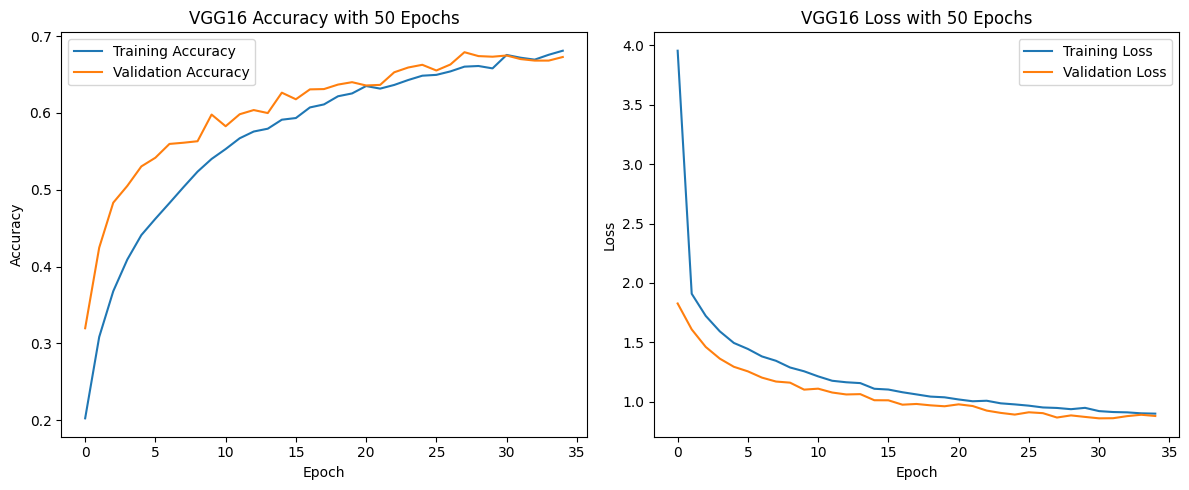

In [31]:
plt.figure(figsize=(12,5))

plt.subplot(1,2,1)

plt.plot(
    history_vgg_50.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history_vgg_50.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.title("VGG16 Accuracy with 50 Epochs")

plt.xlabel("Epoch")

plt.ylabel("Accuracy")

plt.legend()


plt.subplot(1,2,2)

plt.plot(
    history_vgg_50.history["loss"],
    label="Training Loss"
)

plt.plot(
    history_vgg_50.history["val_loss"],
    label="Validation Loss"
)

plt.title("VGG16 Loss with 50 Epochs")

plt.xlabel("Epoch")

plt.ylabel("Loss")

plt.legend()

plt.tight_layout()

plt.show()

# ResNet50 Model

In [32]:
resnet_base = ResNet50(

    weights="imagenet",

    include_top=False,

    input_shape=(128, 128, 3)

)

resnet_base.trainable = False

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 5s 0us/step


In [33]:
resnet_model = models.Sequential([

    layers.Input(shape=(128, 128, 3)),

    models.Sequential([

        layers.RandomFlip("horizontal"),

        layers.RandomRotation(0.10),

        layers.RandomZoom(0.10)

    ]),

    layers.Lambda(
        tf.keras.applications.resnet50.preprocess_input
    ),

    resnet_base,

    layers.GlobalAveragePooling2D(),

    layers.Dense(
        128,
        activation="relu"
    ),

    layers.Dropout(0.5),

    layers.Dense(
        num_classes,
        activation="softmax"
    )

])

In [34]:
resnet_model.compile(

    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.0001
    ),

    loss="sparse_categorical_crossentropy",

    metrics=["accuracy"]

)


early_stop_resnet = tf.keras.callbacks.EarlyStopping(

    monitor="val_loss",

    patience=4,

    restore_best_weights=True

)


history_resnet = resnet_model.fit(

    train_ds,

    validation_data=val_ds,

    epochs=20,

    callbacks=[early_stop_resnet]

)

Epoch 1/20
374/374 ━━━━━━━━━━━━━━━━━━━━ 38s 78ms/step - accuracy: 0.4554 - loss: 1.5510 - val_accuracy: 0.6334 - val_loss: 0.9992
Epoch 2/20
374/374 ━━━━━━━━━━━━━━━━━━━━ 25s 66ms/step - accuracy: 0.6223 - loss: 1.0335 - val_accuracy: 0.6997 - val_loss: 0.8302
Epoch 3/20
374/374 ━━━━━━━━━━━━━━━━━━━━ 25s 66ms/step - accuracy: 0.6769 - loss: 0.8963 - val_accuracy: 0.7024 - val_loss: 0.8290
Epoch 4/20
374/374 ━━━━━━━━━━━━━━━━━━━━ 25s 66ms/step - accuracy: 0.7154 - loss: 0.8102 - val_accuracy: 0.7469 - val_loss: 0.7167
Epoch 5/20
374/374 ━━━━━━━━━━━━━━━━━━━━ 41s 66ms/step - accuracy: 0.7372 - loss: 0.7422 - val_accuracy: 0.7207 - val_loss: 0.7671
Epoch 6/20
374/374 ━━━━━━━━━━━━━━━━━━━━ 25s 66ms/step - accuracy: 0.7523 - loss: 0.7017 - val_accuracy: 0.7289 - val_loss: 0.7498
Epoch 7/20
374/374 ━━━━━━━━━━━━━━━━━━━━ 26s 69ms/step - accuracy: 0.7712 - loss: 0.6619 - val_accuracy: 0.7356 - val_loss: 0.7135
Epoch 8/20
374/374 ━━━━━━━━━━━━━━━━━━━━ 25s 66ms/step - accuracy: 0.7859 - loss: 0.6142 - 

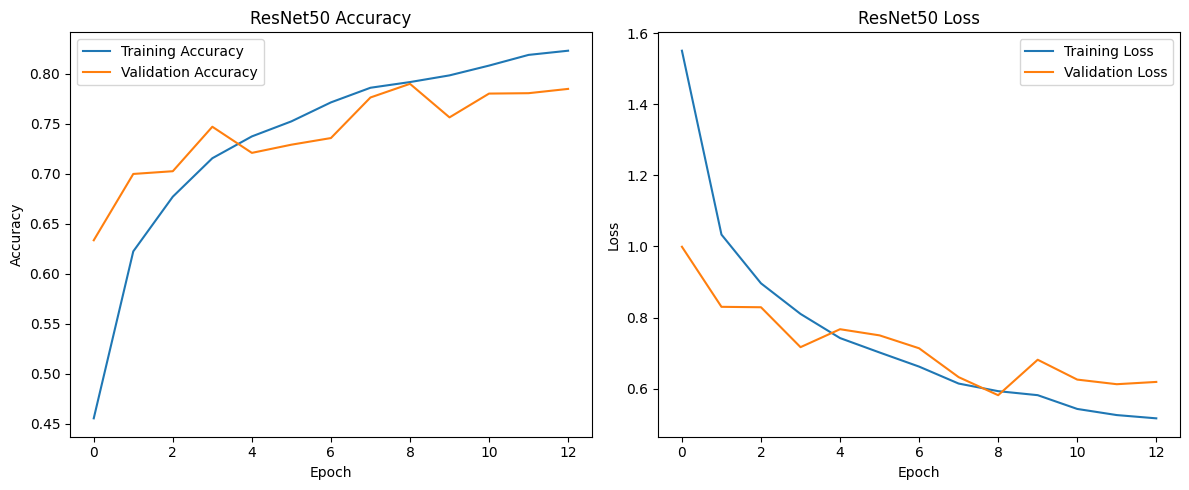

In [35]:
plt.figure(figsize=(12,5))

plt.subplot(1,2,1)

plt.plot(
    history_resnet.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history_resnet.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.title("ResNet50 Accuracy")

plt.xlabel("Epoch")

plt.ylabel("Accuracy")

plt.legend()


plt.subplot(1,2,2)

plt.plot(
    history_resnet.history["loss"],
    label="Training Loss"
)

plt.plot(
    history_resnet.history["val_loss"],
    label="Validation Loss"
)

plt.title("ResNet50 Loss")

plt.xlabel("Epoch")

plt.ylabel("Loss")

plt.legend()

plt.tight_layout()

plt.show()

In [36]:
# ResNet50 with 50 Epochs
resnet_model_50 = models.Sequential([

    layers.Input(shape=(128, 128, 3)),

    models.Sequential([

        layers.RandomFlip("horizontal"),

        layers.RandomRotation(0.10),

        layers.RandomZoom(0.10)

    ]),

    layers.Lambda(
        tf.keras.applications.resnet50.preprocess_input
    ),

    resnet_base,

    layers.GlobalAveragePooling2D(),

    layers.Dense(
        128,
        activation="relu"
    ),

    layers.Dropout(0.5),

    layers.Dense(
        num_classes,
        activation="softmax"
    )

])


resnet_model_50.compile(

    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.0001
    ),

    loss="sparse_categorical_crossentropy",

    metrics=["accuracy"]

)


early_stop_resnet_50 = tf.keras.callbacks.EarlyStopping(

    monitor="val_loss",

    patience=4,

    restore_best_weights=True

)


history_resnet_50 = resnet_model_50.fit(

    train_ds,

    validation_data=val_ds,

    epochs=50,

    callbacks=[early_stop_resnet_50]

)

Epoch 1/50
374/374 ━━━━━━━━━━━━━━━━━━━━ 35s 75ms/step - accuracy: 0.4256 - loss: 1.6151 - val_accuracy: 0.5831 - val_loss: 1.0898
Epoch 2/50
374/374 ━━━━━━━━━━━━━━━━━━━━ 26s 68ms/step - accuracy: 0.6107 - loss: 1.0741 - val_accuracy: 0.6962 - val_loss: 0.8326
Epoch 3/50
374/374 ━━━━━━━━━━━━━━━━━━━━ 25s 66ms/step - accuracy: 0.6785 - loss: 0.9013 - val_accuracy: 0.7145 - val_loss: 0.7760
Epoch 4/50
374/374 ━━━━━━━━━━━━━━━━━━━━ 25s 66ms/step - accuracy: 0.7148 - loss: 0.8041 - val_accuracy: 0.7083 - val_loss: 0.7859
Epoch 5/50
374/374 ━━━━━━━━━━━━━━━━━━━━ 41s 66ms/step - accuracy: 0.7406 - loss: 0.7349 - val_accuracy: 0.7523 - val_loss: 0.6923
Epoch 6/50
374/374 ━━━━━━━━━━━━━━━━━━━━ 25s 66ms/step - accuracy: 0.7583 - loss: 0.6921 - val_accuracy: 0.7422 - val_loss: 0.7009
Epoch 7/50
374/374 ━━━━━━━━━━━━━━━━━━━━ 24s 65ms/step - accuracy: 0.7708 - loss: 0.6559 - val_accuracy: 0.7516 - val_loss: 0.6719
Epoch 8/50
374/374 ━━━━━━━━━━━━━━━━━━━━ 24s 65ms/step - accuracy: 0.7838 - loss: 0.6244 - 

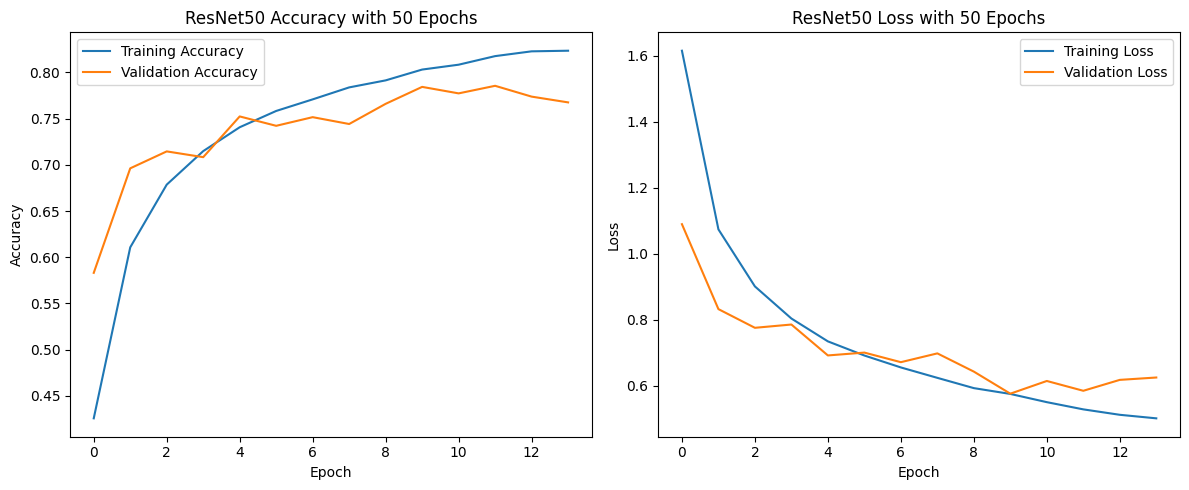

In [37]:
plt.figure(figsize=(12,5))

plt.subplot(1,2,1)

plt.plot(
    history_resnet_50.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history_resnet_50.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.title("ResNet50 Accuracy with 50 Epochs")

plt.xlabel("Epoch")

plt.ylabel("Accuracy")

plt.legend()


plt.subplot(1,2,2)

plt.plot(
    history_resnet_50.history["loss"],
    label="Training Loss"
)

plt.plot(
    history_resnet_50.history["val_loss"],
    label="Validation Loss"
)

plt.title("ResNet50 Loss with 50 Epochs")

plt.xlabel("Epoch")

plt.ylabel("Loss")

plt.legend()

plt.tight_layout()

plt.show()

# Performance Summaries

In [38]:
cnn_loss, cnn_accuracy = cnn_model.evaluate(test_ds)

vgg_loss, vgg_accuracy = vgg_model.evaluate(test_ds)

vgg_loss_50, vgg_accuracy_50 = vgg_model_50.evaluate(test_ds)

resnet_loss, resnet_accuracy = resnet_model.evaluate(test_ds)

resnet_loss_50, resnet_accuracy_50 = resnet_model_50.evaluate(test_ds)


print("Simple CNN Accuracy:", cnn_accuracy)
print("Simple CNN Loss:", cnn_loss)

print("VGG16 Accuracy:", vgg_accuracy)
print("VGG16 Loss:", vgg_loss)

print("VGG16 Accuracy with 50 Epochs:", vgg_accuracy_50)
print("VGG16 Loss with 50 Epochs:", vgg_loss_50)

print("ResNet50 Accuracy:", resnet_accuracy)
print("ResNet50 Loss:", resnet_loss)

print("ResNet50 Accuracy with 50 Epochs:", resnet_accuracy_50)
print("ResNet50 Loss with 50 Epochs:", resnet_loss_50)


81/81 ━━━━━━━━━━━━━━━━━━━━ 3s 32ms/step - accuracy: 0.9212 - loss: 0.2143
81/81 ━━━━━━━━━━━━━━━━━━━━ 4s 46ms/step - accuracy: 0.6712 - loss: 0.9251
81/81 ━━━━━━━━━━━━━━━━━━━━ 4s 49ms/step - accuracy: 0.6888 - loss: 0.8651
81/81 ━━━━━━━━━━━━━━━━━━━━ 4s 48ms/step - accuracy: 0.7980 - loss: 0.5409
81/81 ━━━━━━━━━━━━━━━━━━━━ 4s 48ms/step - accuracy: 0.8019 - loss: 0.5517
Simple CNN Accuracy: 0.9212168455123901
Simple CNN Loss: 0.21426522731781006
VGG16 Accuracy: 0.6712168455123901
VGG16 Loss: 0.9251474738121033
VGG16 Accuracy with 50 Epochs: 0.6887675523757935
VGG16 Loss with 50 Epochs: 0.8651134371757507
ResNet50 Accuracy: 0.7979719042778015
ResNet50 Loss: 0.5409064292907715
ResNet50 Accuracy with 50 Epochs: 0.8018720746040344
ResNet50 Loss with 50 Epochs: 0.5517050623893738


In [39]:
def evaluate_model(model, dataset, model_name):

    # Actual labels
    y_true = np.concatenate([
        labels.numpy()
        for images, labels in dataset
    ])

    # Model predictions
    predictions = model.predict(dataset)

    y_pred = np.argmax(predictions, axis=1)

    # Classification report
    print("\nClassification Report:", model_name)

    report = classification_report(

        y_true,

        y_pred,

        labels=np.arange(num_classes),

        target_names=class_names,

        zero_division=0

    )

    print(report)

    # Confusion matrix
    cm = confusion_matrix(

        y_true,

        y_pred,

        labels=np.arange(num_classes)

    )

    plt.figure(figsize=(8,6))

    sns.heatmap(

        cm,

        annot=True,

        fmt="d",

        cmap="Blues",

        xticklabels=class_names,

        yticklabels=class_names

    )

    plt.title(model_name + " Confusion Matrix")

    plt.xlabel("Predicted Blood Cell Type")

    plt.ylabel("Actual Blood Cell Type")

    plt.tight_layout()

    plt.show()

    return y_true, y_pred

81/81 ━━━━━━━━━━━━━━━━━━━━ 3s 39ms/step

Classification Report: Simple CNN
              precision    recall  f1-score   support

    basophil       0.70      0.99      0.82       183
  eosinophil       1.00      1.00      1.00       467
erythroblast       0.97      0.90      0.93       233
          ig       0.82      0.81      0.81       434
  lymphocyte       0.96      0.97      0.96       182
    monocyte       0.99      0.65      0.78       213
  neutrophil       0.94      0.99      0.97       500
    platelet       1.00      0.98      0.99       352

    accuracy                           0.92      2564
   macro avg       0.92      0.91      0.91      2564
weighted avg       0.93      0.92      0.92      2564



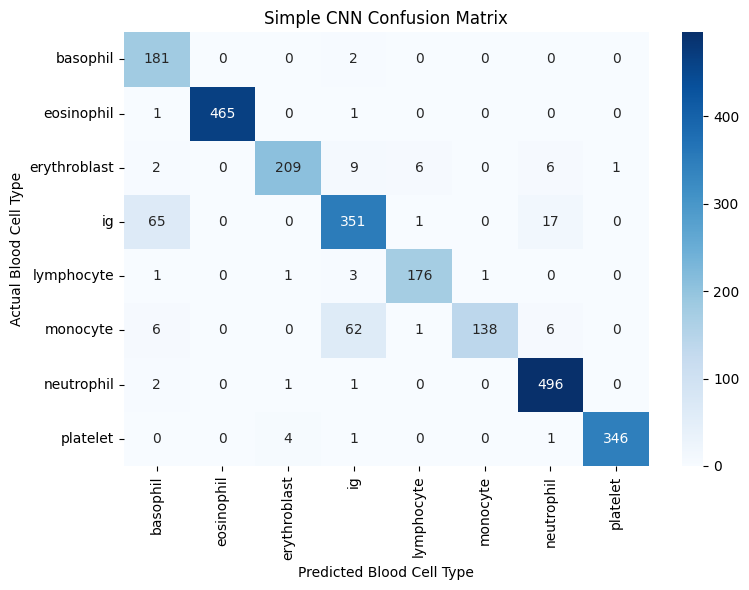

In [40]:
cnn_true, cnn_pred = evaluate_model(

    cnn_model,

    test_ds,

    "Simple CNN"

)

81/81 ━━━━━━━━━━━━━━━━━━━━ 5s 53ms/step

Classification Report: VGG16
              precision    recall  f1-score   support

    basophil       0.61      0.74      0.67       183
  eosinophil       0.57      0.75      0.65       467
erythroblast       0.69      0.71      0.70       233
          ig       0.59      0.82      0.69       434
  lymphocyte       0.70      0.42      0.53       182
    monocyte       0.61      0.41      0.49       213
  neutrophil       0.85      0.56      0.67       500
    platelet       0.91      0.77      0.83       352

    accuracy                           0.67      2564
   macro avg       0.69      0.65      0.65      2564
weighted avg       0.70      0.67      0.67      2564



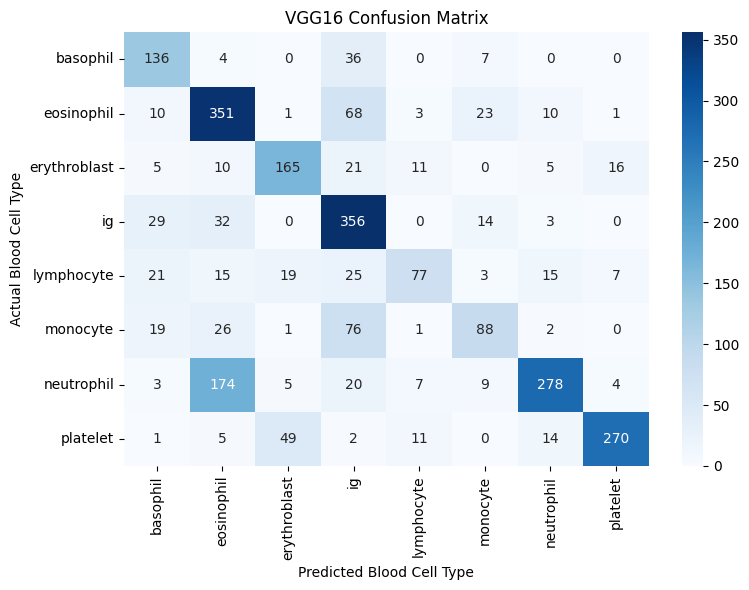

In [41]:
vgg_true, vgg_pred = evaluate_model(

    vgg_model,

    test_ds,

    "VGG16"

)

81/81 ━━━━━━━━━━━━━━━━━━━━ 5s 53ms/step

Classification Report: VGG16 with 50 Epochs
              precision    recall  f1-score   support

    basophil       0.61      0.73      0.67       183
  eosinophil       0.57      0.78      0.66       467
erythroblast       0.75      0.73      0.74       233
          ig       0.61      0.82      0.70       434
  lymphocyte       0.76      0.40      0.52       182
    monocyte       0.63      0.47      0.54       213
  neutrophil       0.84      0.59      0.69       500
    platelet       0.93      0.78      0.85       352

    accuracy                           0.69      2564
   macro avg       0.71      0.66      0.67      2564
weighted avg       0.72      0.69      0.69      2564



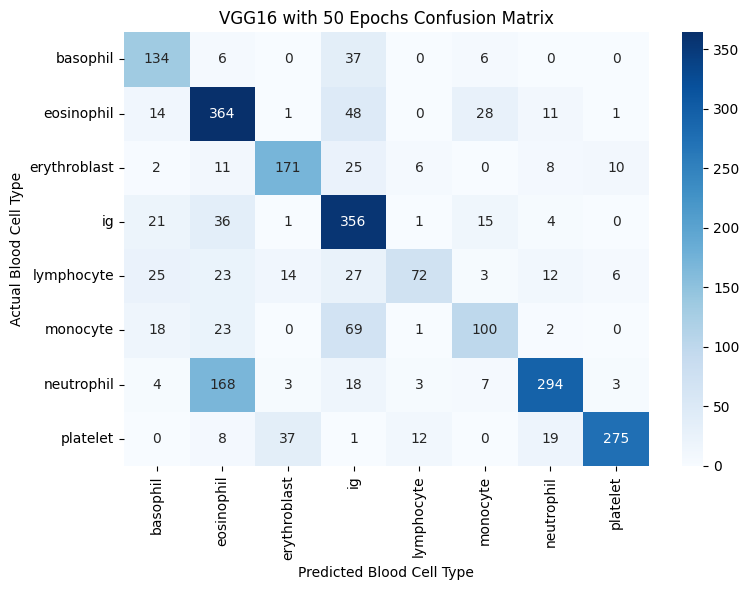

In [42]:
vgg_true_50, vgg_pred_50 = evaluate_model(

    vgg_model_50,

    test_ds,

    "VGG16 with 50 Epochs"

)

81/81 ━━━━━━━━━━━━━━━━━━━━ 8s 73ms/step

Classification Report: ResNet50
              precision    recall  f1-score   support

    basophil       0.74      0.83      0.78       183
  eosinophil       0.72      0.91      0.80       467
erythroblast       0.81      0.86      0.84       233
          ig       0.65      0.89      0.75       434
  lymphocyte       0.96      0.70      0.81       182
    monocyte       0.92      0.38      0.54       213
  neutrophil       0.94      0.70      0.80       500
    platelet       0.99      0.93      0.96       352

    accuracy                           0.80      2564
   macro avg       0.84      0.77      0.78      2564
weighted avg       0.83      0.80      0.79      2564



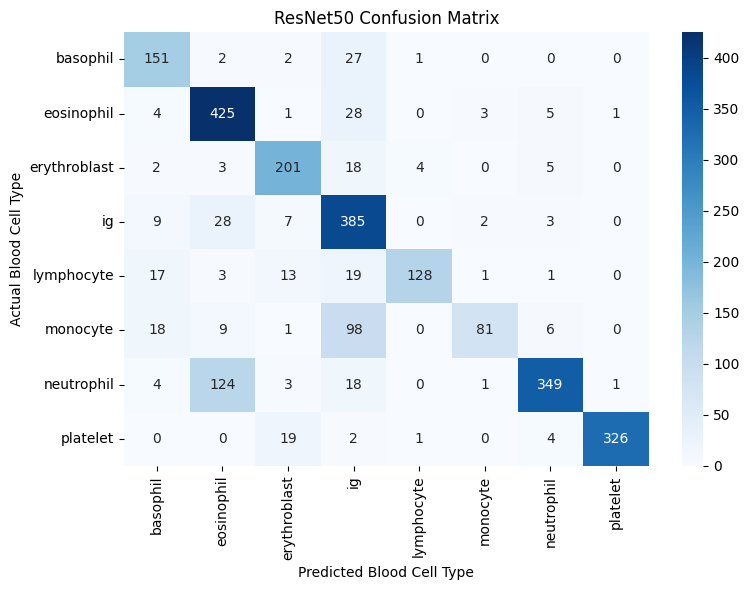

In [43]:
resnet_true, resnet_pred = evaluate_model(

    resnet_model,

    test_ds,

    "ResNet50"

)

81/81 ━━━━━━━━━━━━━━━━━━━━ 8s 75ms/step

Classification Report: ResNet50 with 50 Epochs
              precision    recall  f1-score   support

    basophil       0.68      0.86      0.76       183
  eosinophil       0.74      0.92      0.82       467
erythroblast       0.87      0.82      0.84       233
          ig       0.65      0.90      0.75       434
  lymphocyte       0.95      0.64      0.76       182
    monocyte       0.96      0.31      0.47       213
  neutrophil       0.93      0.75      0.83       500
    platelet       0.99      0.93      0.96       352

    accuracy                           0.80      2564
   macro avg       0.85      0.77      0.78      2564
weighted avg       0.84      0.80      0.79      2564



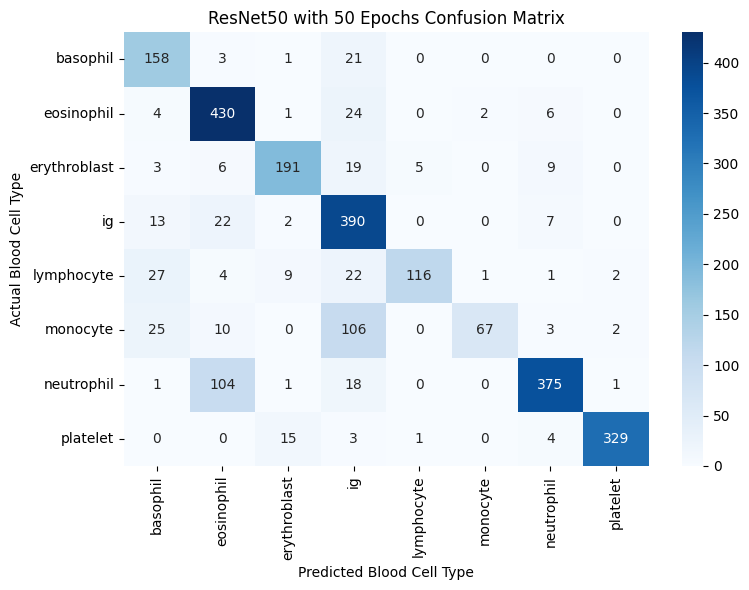

In [44]:
resnet_true_50, resnet_pred_50 = evaluate_model(

    resnet_model_50,

    test_ds,

    "ResNet50 with 50 Epochs"

)

In [45]:
cnn_report = classification_report(
    cnn_true,
    cnn_pred,
    labels=np.arange(num_classes),
    output_dict=True,
    zero_division=0
)

vgg_report = classification_report(
    vgg_true,
    vgg_pred,
    labels=np.arange(num_classes),
    output_dict=True,
    zero_division=0
)

vgg_report_50 = classification_report(
    vgg_true_50,
    vgg_pred_50,
    labels=np.arange(num_classes),
    output_dict=True,
    zero_division=0
)

resnet_report = classification_report(
    resnet_true,
    resnet_pred,
    labels=np.arange(num_classes),
    output_dict=True,
    zero_division=0
)

resnet_report_50 = classification_report(
    resnet_true_50,
    resnet_pred_50,
    labels=np.arange(num_classes),
    output_dict=True,
    zero_division=0
)

In [46]:
results = pd.DataFrame({

    "Model": [
        "Simple CNN",
        "VGG16",
        "VGG16 with 50 Epochs",
        "ResNet50",
        "ResNet50 with 50 Epochs"
    ],

    "Test Accuracy": [
        cnn_accuracy,
        vgg_accuracy,
        vgg_accuracy_50,
        resnet_accuracy,
        resnet_accuracy_50
    ],

    "Test Loss": [
        cnn_loss,
        vgg_loss,
        vgg_loss_50,
        resnet_loss,
        resnet_loss_50
    ],

    "Precision": [
        cnn_report["macro avg"]["precision"],
        vgg_report["macro avg"]["precision"],
        vgg_report_50["macro avg"]["precision"],
        resnet_report["macro avg"]["precision"],
        resnet_report_50["macro avg"]["precision"]
    ],

    "Recall": [
        cnn_report["macro avg"]["recall"],
        vgg_report["macro avg"]["recall"],
        vgg_report_50["macro avg"]["recall"],
        resnet_report["macro avg"]["recall"],
        resnet_report_50["macro avg"]["recall"]
    ],

    "F1-Score": [
        cnn_report["macro avg"]["f1-score"],
        vgg_report["macro avg"]["f1-score"],
        vgg_report_50["macro avg"]["f1-score"],
        resnet_report["macro avg"]["f1-score"],
        resnet_report_50["macro avg"]["f1-score"]
    ]

})

print(results.round(4))

                     Model  Test Accuracy  Test Loss  Precision  Recall  \
0               Simple CNN         0.9212     0.2143     0.9224  0.9101   
1                    VGG16         0.6712     0.9251     0.6900  0.6478   
2     VGG16 with 50 Epochs         0.6888     0.8651     0.7137  0.6625   
3                 ResNet50         0.7980     0.5409     0.8398  0.7741   
4  ResNet50 with 50 Epochs         0.8019     0.5517     0.8451  0.7674   

   F1-Score  
0    0.9084  
1    0.6529  
2    0.6714  
3    0.7840  
4    0.7757  


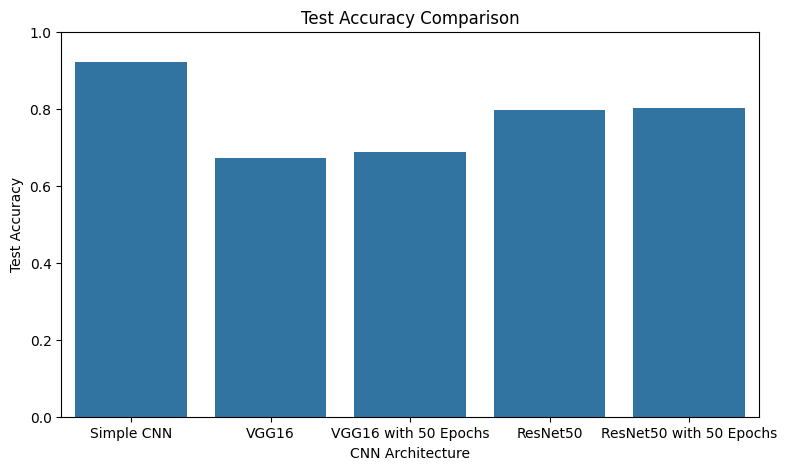

In [47]:
plt.figure(figsize=(9,5))

sns.barplot(

    data=results,

    x="Model",

    y="Test Accuracy"

)

plt.title("Test Accuracy Comparison")

plt.xlabel("CNN Architecture")

plt.ylabel("Test Accuracy")

plt.ylim(0,1)

plt.show()

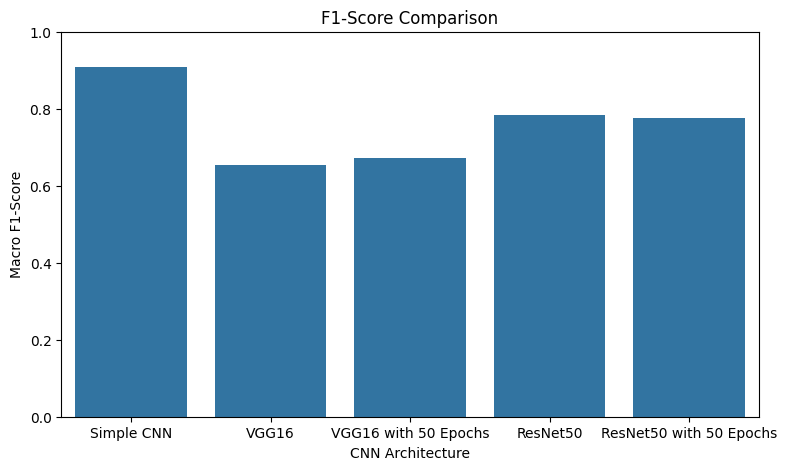

In [48]:
plt.figure(figsize=(9,5))

sns.barplot(

    data=results,

    x="Model",

    y="F1-Score"

)

plt.title("F1-Score Comparison")

plt.xlabel("CNN Architecture")

plt.ylabel("Macro F1-Score")

plt.ylim(0,1)

plt.show()

# Grid Search and Hyperparameter Tuning to find Best CNN Model

In [ ]:
import itertools
import time
from sklearn.metrics import classification_report, accuracy_score

# --- Isolated Grid Search Configuration (No shared variable overrides) ---
GRID_IMG_SIZE = (128, 128)
GRID_MAX_EPOCHS = 35
GRID_PATIENCE = 6

PARAM_GRID = {
    "batch_size": [32, 64],
    "learning_rate": [1e-3, 5e-4],
    "dense_units": [128, 256],
    "dropout_rate": [0.3, 0.5],
    "conv_scale": [1, 2],  # 1 -> (32, 64, 128), 2 -> (64, 128, 256)
}


def _grid_load_image(image_path, label):
    image = tf.io.read_file(image_path)
    image = tf.io.decode_image(image, channels=3, expand_animations=False)
    image = tf.image.resize(image, GRID_IMG_SIZE)
    image = tf.cast(image, tf.float32)
    image.set_shape((GRID_IMG_SIZE[0], GRID_IMG_SIZE[1], 3))
    return image, label


def build_grid_dataset(dataframe, batch_size, shuffle=False):
    paths = dataframe["image_path"].values
    labels = dataframe["label_id"].values
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    if shuffle:
        ds = ds.shuffle(buffer_size=len(dataframe), seed=SEED)
    ds = ds.map(_grid_load_image, num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.batch(batch_size)
    ds = ds.prefetch(tf.data.AUTOTUNE)
    return ds


def build_grid_cnn_model(params):
    f1 = 32 * params["conv_scale"]
    f2 = 64 * params["conv_scale"]
    f3 = 128 * params["conv_scale"]

    grid_aug = models.Sequential(
        [
            layers.RandomFlip("horizontal"),
            layers.RandomRotation(0.10),
            layers.RandomZoom(0.10),
        ],
        name="grid_data_augmentation",
    )

    model = models.Sequential(
        [
            layers.Input(shape=(GRID_IMG_SIZE[0], GRID_IMG_SIZE[1], 3)),
            grid_aug,
            layers.Rescaling(1.0 / 255.0),
            layers.Conv2D(f1, (3, 3), padding="same", activation="relu"),
            layers.BatchNormalization(),
            layers.MaxPooling2D((2, 2)),
            layers.Conv2D(f2, (3, 3), padding="same", activation="relu"),
            layers.BatchNormalization(),
            layers.MaxPooling2D((2, 2)),
            layers.Conv2D(f3, (3, 3), padding="same", activation="relu"),
            layers.BatchNormalization(),
            layers.MaxPooling2D((2, 2)),
            layers.GlobalAveragePooling2D(),
            layers.Dense(params["dense_units"], activation="relu"),
            layers.Dropout(params["dropout_rate"]),
            layers.Dense(num_classes, activation="softmax"),
        ],
        name="grid_search_cnn",
    )

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=params["learning_rate"]),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )
    return model


# --- Execute Grid Search ---
grid_keys = list(PARAM_GRID.keys())
grid_combinations = [
    dict(zip(grid_keys, combo))
    for combo in itertools.product(*(PARAM_GRID[k] for k in grid_keys))
]

print(f"Total hyperparameter combinations to evaluate: {len(grid_combinations)}")

grid_search_records = []
best_grid_val_acc = -1.0
best_grid_params = None
best_grid_model = None
best_grid_history = None

# Cache datasets per batch_size so we don't rebuild them redundantly
grid_ds_cache = {}
for bs in PARAM_GRID["batch_size"]:
    grid_ds_cache[bs] = (
        build_grid_dataset(train_data, bs, shuffle=True),
        build_grid_dataset(val_data, bs, shuffle=False),
        build_grid_dataset(test_data, bs, shuffle=False),
    )

for idx, params in enumerate(grid_combinations, start=1):
    tf.keras.backend.clear_session()
    np.random.seed(SEED + idx)
    tf.random.set_seed(SEED + idx)

    start_time = time.time()
    grid_train_ds, grid_val_ds, grid_test_ds = grid_ds_cache[params["batch_size"]]

    candidate_model = build_grid_cnn_model(params)

    grid_callbacks = [
        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=GRID_PATIENCE,
            restore_best_weights=True,
        ),
        tf.keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.5,
            patience=3,
            min_lr=1e-6,
            verbose=0,
        ),
    ]

    candidate_history = candidate_model.fit(
        grid_train_ds,
        validation_data=grid_val_ds,
        epochs=GRID_MAX_EPOCHS,
        callbacks=grid_callbacks,
        verbose=0,
    )

    elapsed_sec = round(time.time() - start_time, 1)
    best_epoch_val_acc = max(candidate_history.history["val_accuracy"])
    best_epoch_val_loss = min(candidate_history.history["val_loss"])
    epochs_ran = len(candidate_history.history["loss"])

    record = {
        "trial": idx,
        **params,
        "epochs_ran": epochs_ran,
        "best_val_accuracy": round(float(best_epoch_val_acc), 4),
        "best_val_loss": round(float(best_epoch_val_loss), 4),
        "train_time_sec": elapsed_sec,
    }
    grid_search_records.append(record)

    print(
        f"[{idx}/{len(grid_combinations)}] params={params} -> "
        f"val_acc={best_epoch_val_acc:.4f}, val_loss={best_epoch_val_loss:.4f}, "
        f"epochs={epochs_ran}/{GRID_MAX_EPOCHS} ({elapsed_sec}s)"
    )

    if best_epoch_val_acc > best_grid_val_acc:
        best_grid_val_acc = float(best_epoch_val_acc)
        best_grid_params = params.copy()
        best_grid_model = candidate_model
        best_grid_history = candidate_history

# --- Summary Table Sorted by Best Validation Accuracy ---
grid_results_df = pd.DataFrame(grid_search_records).sort_values(
    by=["best_val_accuracy", "best_val_loss"],
    ascending=[False, True],
).reset_index(drop=True)

print("\n=== Grid Search Leaderboard (Top 10) ===")
print(grid_results_df.head(10).to_string(index=False))
print("\nBest Hyperparameters:", best_grid_params)

# --- Evaluate Best Grid Model on Held-Out Test Set ---
_, _, best_grid_test_ds = grid_ds_cache[best_grid_params["batch_size"]]
best_grid_test_loss, best_grid_test_acc = best_grid_model.evaluate(
    best_grid_test_ds, verbose=0
)

grid_y_true = np.concatenate([labels.numpy() for _, labels in best_grid_test_ds])
grid_y_pred = np.argmax(best_grid_model.predict(best_grid_test_ds, verbose=0), axis=1)

print(f"\nBest Grid Model Test Accuracy: {best_grid_test_acc:.4f}")
print(f"Best Grid Model Test Loss:     {best_grid_test_loss:.4f}")
print("\nClassification Report (Best Grid Model):")
print(
    classification_report(
        grid_y_true,
        grid_y_pred,
        labels=np.arange(num_classes),
        target_names=class_names,
        zero_division=0,
    )
)

# --- Append to a Separate Comparison Table (Leaves `results` Untouched) ---
grid_report_dict = classification_report(
    grid_y_true,
    grid_y_pred,
    labels=np.arange(num_classes),
    output_dict=True,
    zero_division=0,
)

grid_comparison_df = pd.DataFrame(
    [
        {
            "Model": "Simple CNN (Original)",
            "Test Accuracy": cnn_accuracy,
            "Test Loss": cnn_loss,
            "Precision": cnn_report["macro avg"]["precision"],
            "Recall": cnn_report["macro avg"]["recall"],
            "F1-Score": cnn_report["macro avg"]["f1-score"],
        },
        {
            "Model": "VGG16 (Original)",
            "Test Accuracy": vgg_accuracy,
            "Test Loss": vgg_loss,
            "Precision": vgg_report["macro avg"]["precision"],
            "Recall": vgg_report["macro avg"]["recall"],
            "F1-Score": vgg_report["macro avg"]["f1-score"],
        },
        {
            "Model": "ResNet50 (Original)",
            "Test Accuracy": resnet_accuracy,
            "Test Loss": resnet_loss,
            "Precision": resnet_report["macro avg"]["precision"],
            "Recall": resnet_report["macro avg"]["recall"],
            "F1-Score": resnet_report["macro avg"]["f1-score"],
        },
        {
            "Model": "Grid Search Best CNN",
            "Test Accuracy": best_grid_test_acc,
            "Test Loss": best_grid_test_loss,
            "Precision": grid_report_dict["macro avg"]["precision"],
            "Recall": grid_report_dict["macro avg"]["recall"],
            "F1-Score": grid_report_dict["macro avg"]["f1-score"],
        },
    ]
)

print("\n=== Combined Model Comparison (New DataFrame) ===")
print(grid_comparison_df.round(4).to_string(index=False))

In [ ]:
# Plot Training & Validation Accuracy and Loss for the Best Grid Search Model
plt.figure(figsize=(12, 5))

# Accuracy Subplot
plt.subplot(1, 2, 1)
plt.plot(best_grid_history.history["accuracy"], label="Training Accuracy")
plt.plot(best_grid_history.history["val_accuracy"], label="Validation Accuracy")
plt.title(f"Best Grid CNN Accuracy (Params: {best_grid_params})")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

# Loss Subplot
plt.subplot(1, 2, 2)
plt.plot(best_grid_history.history["loss"], label="Training Loss")
plt.plot(best_grid_history.history["val_loss"], label="Validation Loss")
plt.title("Best Grid CNN Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
cm_best = confusion_matrix(grid_y_true, grid_y_pred, labels=np.arange(num_classes))

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm_best,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)
plt.title("Best Grid Search CNN Confusion Matrix")
plt.xlabel("Predicted Blood Cell Type")
plt.ylabel("Actual Blood Cell Type")
plt.tight_layout()
plt.show()